# Landmarks of the Wikipedia game: final reproducible analysis

This notebook starts from the **processed data** (`data/processed/`), re-runs the analysis and regenerates every figure. Raw data are obtained with `uv run python run.py download parse clean` (see README).

**Question.** Are the pages that players use as landmarks (countries, general pages, link-rich pages) the best hubs for connecting any two French Wikipedia articles? If not, which pages are?

In [1]:
import os, json
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
import pandas as pd
from IPython.display import Image, display
from wikigame import analysis, figures
from wikigame.common import load_config, path, read_json
cfg = load_config(); A = cfg['analysis']
out = path(cfg, 'generated') / f"sample_seed{A['seed']}_n{A['n_pairs']}"
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)

## 1. Data quality and cleaning (computed by `clean.py`)

In [2]:
q = read_json(path(cfg, 'processed') / 'quality.json')
print(json.dumps({k: q[k] for k in ['articles', 'edges', 'degrees', 'disambiguation']}, indent=1))

{
 "articles": 2782511,
 "edges": {
  "candidate_edges": 238762721,
  "self_loops": 53339,
  "duplicates_after_redirect_resolution": 2806457,
  "final_edges": 235902925
 },
 "degrees": {
  "nodes": 2782511,
  "sinks_out_degree_0": 256,
  "orphans_in_degree_0": 46349,
  "isolated_both_0": 133,
  "disambiguation_nodes": 180041,
  "mean_out_degree": 84.78059026541135,
  "median_out_degree": 40.0,
  "max_out_degree": 5374,
  "median_in_degree": 14.0,
  "max_in_degree": 579086
 },
 "disambiguation": {
  "pages_flagged": 180169,
  "flagged_articles": 180041,
  "flagged_ns0_redirects": 82,
  "flagged_missing_page": 0
 }
}


## 2. Analysis (re-run from the cache)

BFS results are cached in `data/processed/cache`; this cell recomputes all metrics from them.

In [3]:
analysis.main()
res = read_json(out / 'results.json')
print(json.dumps({k: res[k] for k in ['graph', 'largest_scc', 'pairs', 'candidates']}, indent=1))

18:07:27 analysis INFO start: largest SCC


18:07:27 analysis INFO hubs: 1 requested, 0 to compute (2 BFS each)


18:07:27 analysis INFO done: largest SCC in 0.0 s


18:07:27 analysis INFO start: pairs


18:07:28 analysis INFO pairs: 200000 in sample, 200000 cached, 0 to compute


18:07:28 analysis INFO done: pairs in 1.1 s


... (3 outputs left out)

18:07:29 analysis INFO start: hub metrics


18:07:42 analysis INFO done: hub metrics in 12.4 s


18:07:42 analysis INFO results written to C:\Users\Joshs\Desktop\lab\DDS Final Project\reports\generated\sample_seed42_n200000


{
 "graph": {
  "nodes": 2782511,
  "edges": 235902925,
  "out_degree_quantiles": {
   "0.25": 21.0,
   "0.5": 40.0,
   "0.75": 93.0,
   "0.9": 203.0,
   "0.99": 612.0
  },
  "in_degree_quantiles": {
   "0.25": 4.0,
   "0.5": 14.0,
   "0.75": 59.0,
   "0.9": 160.0,
   "0.99": 863.0
  },
  "disambiguation_nodes": 180041
 },
 "largest_scc": {
  "root_node": 618875,
  "root_title": "Autorit\u00e9_(sciences_de_l'information)",
  "size": 2731950,
  "share_of_nodes": 0.9818290026526401,
  "is_largest_proven": true,
  "reachable_from_root": 2732071,
  "reaching_root": 2782255
 },
 "pairs": {
  "n": 200000,
  "reachable": 197235,
  "unreachable": 2765,
  "unreachable_share": 0.013825,
  "distance_distribution": {
   "1": 8,
   "2": 778,
   "3": 33757,
   "4": 115597,
   "5": 41514,
   "6": 5180,
   "7": 323,
   "8": 36,
   "9": 11,
   "10": 7,
   "11": 4,
   "12": 3,
   "13": 4,
   "14": 2,
   "15": 4,
   "16": 1,
   "17": 2,
   "18": 2,
   "25": 1,
   "29": 1
  },
  "mean_distance": 4.0913174

## 3. Perceived vs real

*Observations* only; interpretation is in the report.

In [4]:
print(json.dumps(res['perceived_vs_real'], indent=1))

{
 "spearman_out_degree_vs_mean_detour_candidates": {
  "rho": 0.284851528140887,
  "p_value": 4.941965523166656e-06,
  "n": 249
 },
 "spearman_out_degree_vs_on_path_candidates": {
  "rho": -0.3838823619758274,
  "p_value": 3.6357521856352436e-10,
  "n": 249
 },
 "spearman_in_degree_vs_mean_detour_candidates": {
  "rho": -0.5801036593110593,
  "p_value": 8.589931624640758e-24,
  "n": 249
 },
 "spearman_in_degree_vs_on_path_candidates": {
  "rho": 0.6951678071446595,
  "p_value": 2.8216120413903333e-37,
  "n": 249
 },
 "spearman_out_degree_vs_mean_detour_all_evaluated": {
  "rho": -0.1512126802995525,
  "p_value": 0.00882306346214067,
  "n": 299
 },
 "spearman_out_degree_vs_mean_detour_random_baseline": {
  "rho": -0.5644437105011278,
  "p_value": 1.959586578657049e-05,
  "n": 50
 },
 "top50_overlap_out_degree_vs_mean_detour": 2,
 "top50_overlap_out_degree_vs_on_path": 2,
 "mean_detour_by_group": {
  "top_out_degree": {
   "n": 100,
   "n_rankable": 100,
   "mean_of_mean_detour": 2.9006

In [5]:
hubs = pd.read_csv(out / 'hubs.csv')
if Path('labels/hub_type_labels.csv').exists():
    hubs = hubs.merge(pd.read_csv('labels/hub_type_labels.csv')[['page_id', 'type']], on='page_id', how='left')
else:
    hubs['type'] = None
cols = ['title', 'type', 'out_degree', 'in_degree', 'path_frequency', 'mean_detour', 'on_path_rate', 'pairs_h_not_connected']
print('Best 20 hubs by mean detour (coverage >= min_coverage)'); display(hubs.sort_values('mean_detour_ranked')[cols].head(20))
print('Top 20 by out-degree (perceived)'); display(hubs.sort_values('out_degree', ascending=False)[cols].head(20))

Best 20 hubs by mean detour (coverage >= min_coverage)


,title,type,out_degree,in_degree,path_frequency,mean_detour,on_path_rate,pairs_h_not_connected
0,France,country,2789,555633,11417,0.920678,0.244774,0
1,États-Unis,country,1865,408575,6607,1.090491,0.162628,0
2,Paris,city,2859,166272,3493,1.127731,0.142759,0
3,Canada,country,1911,130782,1928,1.234858,0.082009,0
4,Italie,country,1380,150382,1830,1.254493,0.077076,0
5,Royaume-Uni,country,1397,164371,1914,1.256466,0.080173,0
6,Europe,continent,1267,86721,817,1.299938,0.063336,0
7,Portugal,country,2282,38238,787,1.312216,0.054083,0
8,New_York,city,1449,66687,1012,1.317281,0.066976,0
9,Suisse,country,1314,82905,909,1.325013,0.053130,0


Top 20 by out-degree (perceived)


,title,type,out_degree,in_degree,path_frequency,mean_detour,on_path_rate,pairs_h_not_connected
284,Liste_des_cantons_français_au_Grand_Est_depuis...,list,5374,14,0,4.197161,0.000015,0
217,Liste_des_bureaux_de_poste_français_classés_pa...,list,5346,11,1,3.293427,0.000122,0
119,Décès_en_2024,list,4888,293,41,2.152174,0.002758,0
204,Chronologie_de_Google_Street_View,list,4885,1,5,3.179436,0.000223,0
132,Décès_en_2025,list,4866,256,50,2.275544,0.003301,0
280,Liste_des_cantons_français_en_Occitanie_depuis...,list,4828,14,0,4.175577,0.000020,0
184,Liste_de_localités_de_Serbie,list,4770,6215,184,2.942688,0.002560,0
214,Liste_de_gares_en_France,list,4621,4373,94,3.261749,0.001567,0
247,Liste_des_bureaux_de_poste_français_classés_pa...,list,4615,10,0,3.508039,0.000041,0
283,Liste_des_cantons_français_en_Nouvelle-Aquitai...,list,4605,14,0,4.194448,0.000010,0


## 4. Bias check (template inflation of out-degree)

In [6]:
bc = path(cfg, 'generated') / 'bias_check.json'
print(json.dumps(read_json(bc), indent=1) if bc.exists() else 'run: python run.py bias')

{
 "n_pages": 200,
 "n_errors": 0,
 "removed_selectors": [
  ".navbox-container",
  ".navbox",
  ".navigation-only",
  "#bandeau-portail",
  ".bandeau-portail"
 ],
 "random": {
  "n": 50,
  "median_dump_out_degree": 55.5,
  "median_html_all": 55.5,
  "median_body": 30.0,
  "median_template_share": 0.2611451048951049,
  "mean_template_share": 0.3555628070961932,
  "median_ratio_html_all_to_dump": 1.0
 },
 "top_in_degree": {
  "n": 50,
  "median_dump_out_degree": 352.0,
  "median_html_all": 352.0,
  "median_body": 223.5,
  "median_template_share": 0.23909331149920082,
  "mean_template_share": 0.2954623794271665,
  "median_ratio_html_all_to_dump": 1.0
 },
 "top_out_degree": {
  "n": 100,
  "median_dump_out_degree": 2524.0,
  "median_html_all": 2524.0,
  "median_body": 2520.5,
  "median_template_share": 0.0050355649501149236,
  "mean_template_share": 0.08873594576950512,
  "median_ratio_html_all_to_dump": 1.0
 },
 "top_group_spearman_dump_vs_body": {
  "rho": 0.9022406132994352,
  "p_value

## 5. Figures

18:07:43 figures INFO wrote fig_degree_ccdf


18:07:43 figures INFO wrote fig_distance_distribution


18:07:44 figures INFO wrote fig_detour_vs_outdegree


18:07:44 figures INFO wrote fig_best_hubs


18:07:44 figures INFO wrote fig_detour_by_type


18:07:45 figures INFO wrote fig_bias_check


... (7 outputs left out)

18:07:47 figures INFO wrote s_robustness


18:07:47 figures INFO wrote s_storage


18:07:47 figures INFO wrote s_bias_bars


fig_best_hubs.png


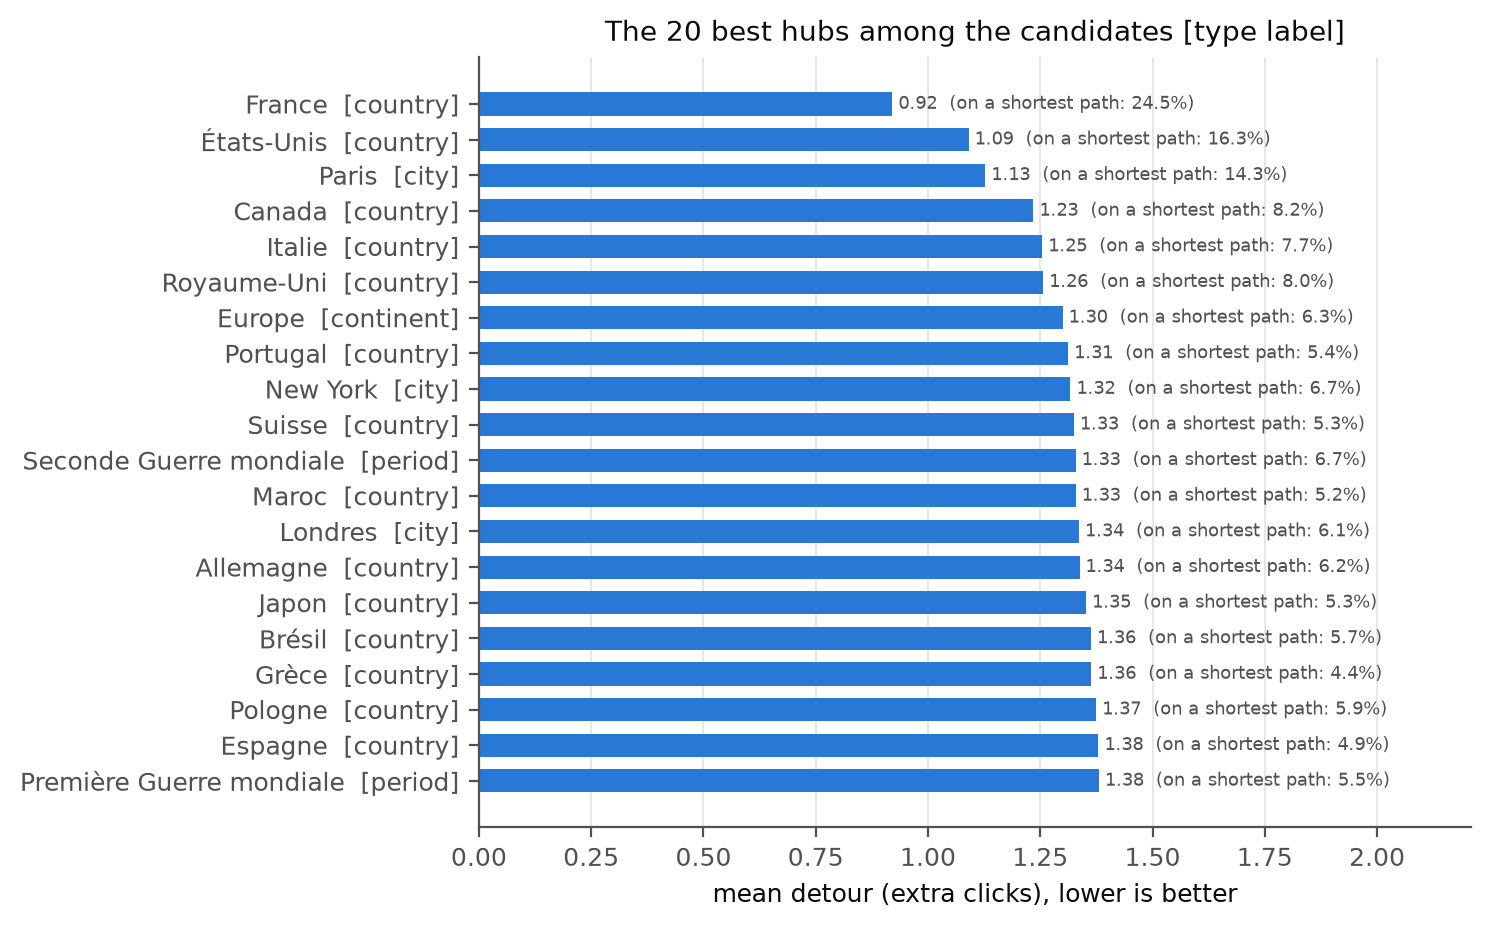

fig_bias_check.png


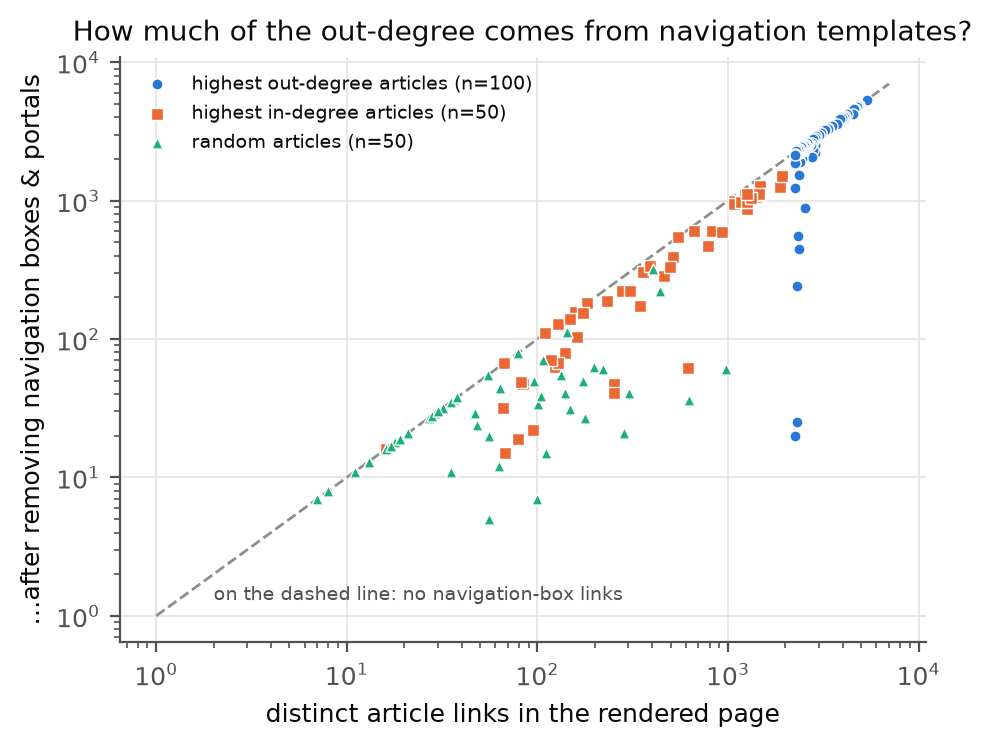

fig_degree_ccdf.png


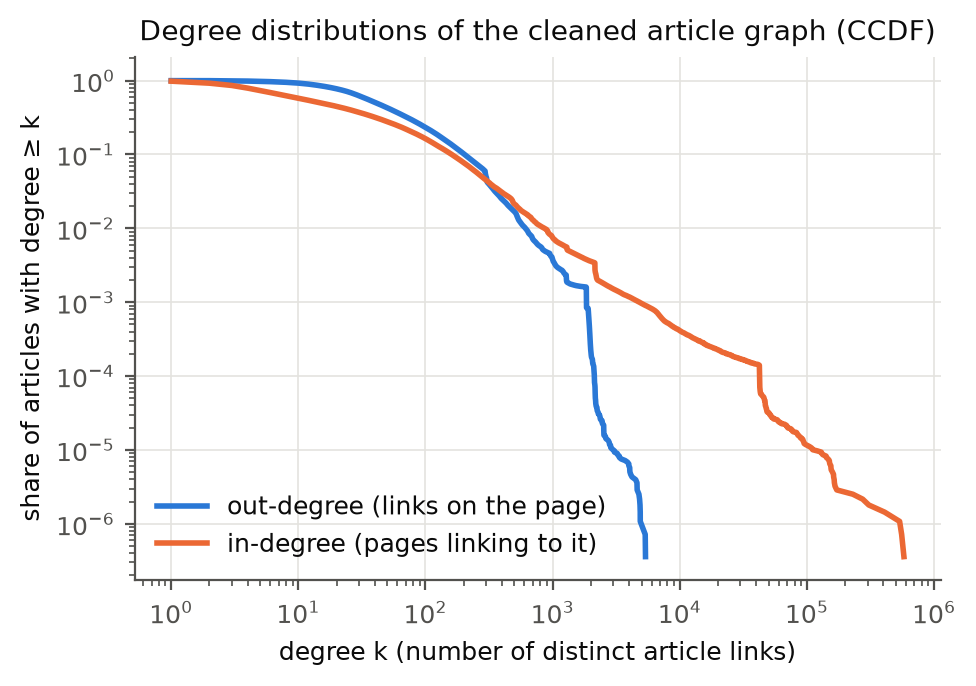

fig_detour_by_type.png


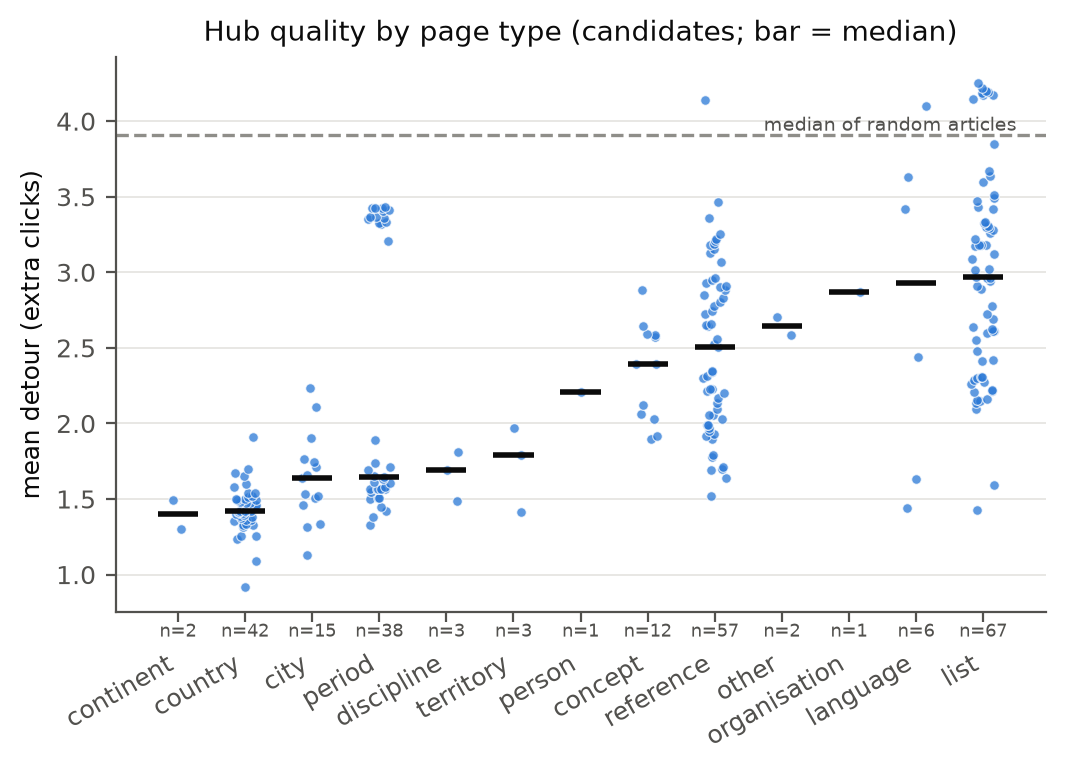

fig_detour_vs_outdegree.png


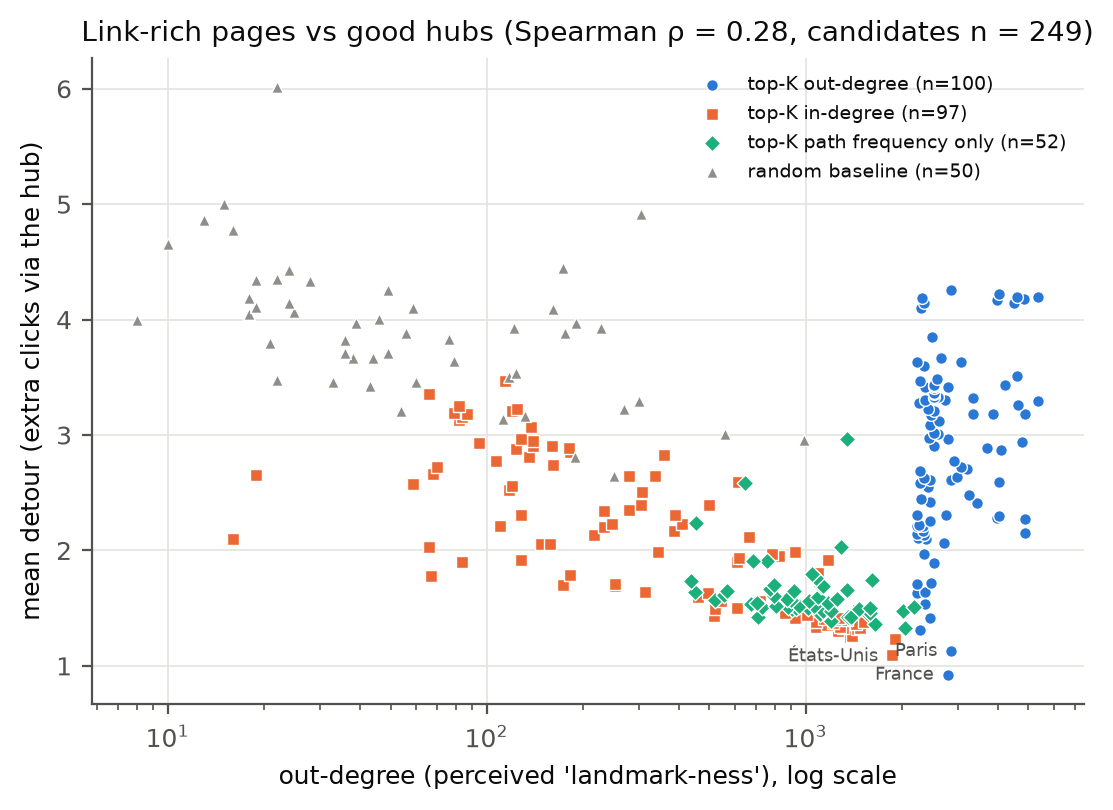

fig_distance_distribution.png


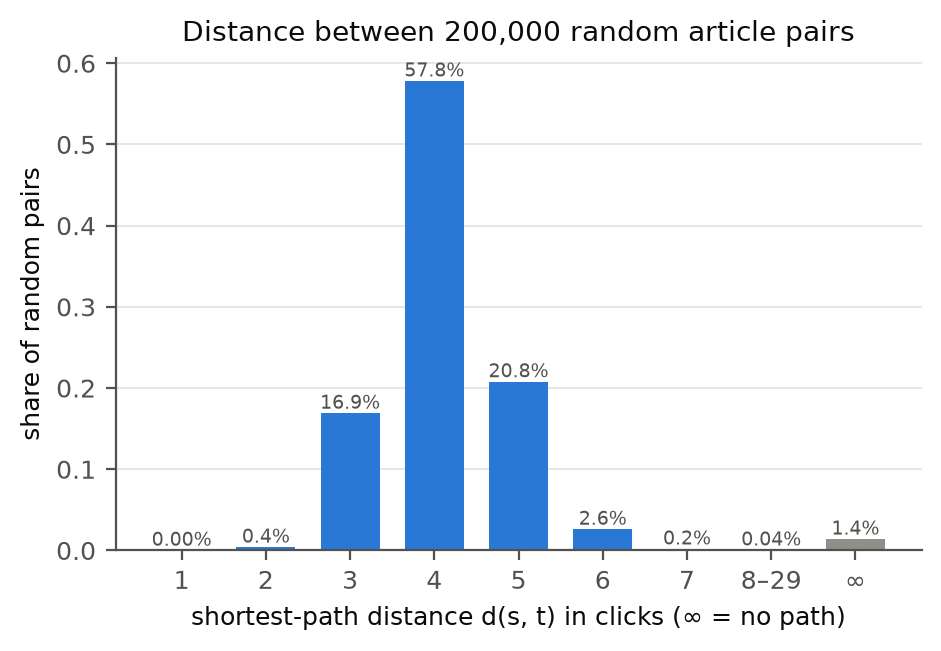

In [7]:
figures.main()
for f in sorted(path(cfg, 'figures').glob('*.png')):
    print(f.name); display(Image(filename=str(f), width=720))